# Project 6: Energy Consumption Dashboard
Notebook membaca CSV hasil (`results/`), tidak menghitung ulang. Urutan mengikuti 14 pertanyaan pada Design Project. Tarif Rp1.650/Rp1.100 per kWh adalah asumsi.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
R1, R2 = "../1-data-preparation/", "../2-analysis/"
rd = lambda p: pd.read_csv(p)

## Q1-Q2. Profil beban per jam, hari kerja vs akhir pekan

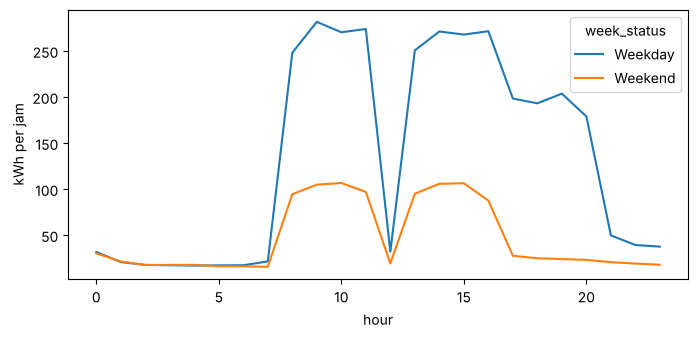

     wk  hari  kwh_per_hari     std  rasio_terhadap_weekday  jam_tertinggi  kwh_jam_tertinggi
Weekday   261       3227.97 1184.50                    1.00              9             281.62
Weekend   104       1126.30 1005.91                    0.35             10             106.61


In [2]:
h = rd(R2+"hour_profile.csv").pivot(index="hour", columns="week_status", values="avg_kwh_per_hour"); h.plot(figsize=(8,3.5)); plt.ylabel("kWh per jam"); plt.show()
print(rd(R2+"weekday_weekend.csv").round(2).to_string(index=False))

## Q3. Tren bulanan

In [3]:
print(rd(R2+'monthly.csv').round(0).to_string(index=False))

 month  total_kwh        cost  peak_cost  peak_kwh  co2_t  peak_kw
     1   126238.0 155759258.0 50691416.0   30722.0   54.0    613.0
     2    91497.0 114457536.0 41431384.0   25110.0   39.0    582.0
     3    80230.0  97962766.0 29127945.0   17653.0   34.0    605.0
     4    78770.0  96895034.0 30744764.0   18633.0   33.0    556.0
     5    79059.0  97641550.0 32029024.0   19412.0   34.0    560.0
     6    65405.0  80681430.0 26208980.0   15884.0   27.0    535.0
     7    81674.0 100932469.0 33271854.0   20165.0   35.0    487.0
     8    68559.0  84381902.0 26899587.0   16303.0   28.0    535.0
     9    57883.0  70438764.0 20302161.0   12304.0   24.0    510.0
    10    84666.0 104916350.0 35352405.0   21426.0   36.0    558.0
    11    86218.0 105754402.0 32745092.0   19846.0   37.0    629.0
    12    59437.0  70904042.0 16570752.0   10043.0   23.0    597.0


## Q4. Load_Type per jam

In [4]:
print(rd(R2+'loadtype_summary.csv').round(3).to_string(index=False)); print(rd(R2+'maximum_by_hour.csv').round(3).to_string(index=False))

   load_type     n       kwh  porsi_waktu  porsi_energi
  Light_Load 18072 155892.81        0.516         0.162
Maximum_Load  7272 430977.36        0.208         0.449
 Medium_Load  9696 372766.54        0.277         0.388
 hour  n_maximum  porsi  kumulatif
   10       1212  0.167      0.167
   11       1212  0.167      0.333
   13        832  0.114      0.448
   14        832  0.114      0.562
   16        832  0.114      0.677
   15        832  0.114      0.791
   18        380  0.052      0.843
   17        380  0.052      0.895
   22        380  0.052      0.948
   19        380  0.052      1.000
    5          0  0.000      1.000
    4          0  0.000      1.000
    3          0  0.000      1.000
    2          0  0.000      1.000
    1          0  0.000      1.000
    0          0  0.000      1.000
    7          0  0.000      1.000
    6          0  0.000      1.000
    9          0  0.000      1.000
    8          0  0.000      1.000
   12          0  0.000      1.000
   20 

## Q5. Kejadian beban tinggi (di atas P90)

In [5]:
print(rd(R2+'high_load_summary.csv').T.to_string(header=False)); print(rd(R2+'high_load_events.csv').head(10).to_string(index=False))

ambang_kwh_interval           78.084000
persentil                      0.900000
n_kejadian                   983.000000
durasi_median_jam              0.500000
durasi_p90_jam                 2.000000
durasi_maks_jam                7.500000
kejadian_per_hari              2.693151
porsi_waktu_di_atas            0.100000
jam_mulai_tersering           13.000000
porsi_mulai_jam_tersering      0.138352
kejadian_mulai_di_blok_peak    0.234995
              mulai  n_interval     kwh  peak_kw  durasi_jam  jam_mulai
2018-01-02 10:30:00           1   80.21   320.84        0.25         10
2018-01-02 11:00:00           4  487.15   577.88        1.00         11
2018-01-02 13:00:00          16 1819.51   589.84        4.00         13
2018-01-02 17:15:00           2  228.89   463.12        0.50         17
2018-01-03 08:30:00           4  450.83   487.16        1.00          8
2018-01-03 11:15:00           1   78.62   314.48        0.25         11
2018-01-03 16:00:00           7  805.68   562.04        

## Q6-Q7. Biaya per bulan dan per hari dalam seminggu

In [6]:
print(rd(R2+'dow_cost.csv').round(0).to_string(index=False)); print(rd(R2+'kpi_year.csv').T.to_string(header=False))

day_of_week  n_days  avg_cost_per_day  avg_kwh_per_day
   Thursday      52         4192308.0           3371.0
    Tuesday      52         4118711.0           3305.0
     Monday      53         3968686.0           3182.0
     Friday      52         3955557.0           3187.0
  Wednesday      52         3784540.0           3096.0
   Saturday      52         1762303.0           1528.0
     Sunday      52          847834.0            724.0
n_intervals      3.504000e+04
total_kwh        9.596367e+05
cost             1.180726e+09
peak_cost        3.753754e+08
peak_kwh         2.275002e+05
peak_kw          6.287200e+02
co2_t            4.038100e+02
peak_cost_share  3.179192e-01
load_factor      1.742390e-01


## Q8-Q9. Power factor rendah

In [7]:
print(rd(R2+'pf_by_load.csv').round(3).to_string(index=False)); print(rd(R2+'pf_hour.csv').round(3).T.to_string(header=False))

   load_type     n  n_low  porsi_rendah
  Light_Load 18072  13901         0.769
Maximum_Load  7272   1037         0.143
 Medium_Load  9696    973         0.100
hour             0.000     1.000     2.000     3.00     4.000     5.000     6.000     7.00     8.00     9.00    10.000    11.00    12.000    13.000    14.000    15.000    16.000    17.000    18.000    19.000    20.000    21.0    22.000    23.000
n_intervals   1460.000  1460.000  1460.000  1460.00  1460.000  1460.000  1460.000  1460.00  1460.00  1460.00  1460.000  1460.00  1460.000  1460.000  1460.000  1460.000  1460.000  1460.000  1460.000  1460.000  1460.000  1460.0  1460.000  1460.000
n_low_pf      1354.000  1398.000  1404.000  1445.00  1455.000  1443.000  1443.000  1373.00  1037.00    59.00    55.000   452.00     6.000    79.000    66.000    65.000    47.000    22.000   147.000    52.000    27.000     0.0  1141.000  1341.000
porsi_rendah     0.927     0.958     0.962     0.99     0.997     0.988     0.988     0.94     0.71   

## Q10-Q12. Skenario pemindahan beban (estimated)

In [8]:
print(rd(R2+'dest_hours.csv').round(1).to_string(index=False)); print(rd(R2+'scenarios.csv').round(1).T.to_string(header=False))

 hour  kwh_rata2  kwh_maks     blok  tarif  dipilih_tujuan  peringkat_beban_terendah
    0       31.3     361.8 Off-peak   1100           False                         9
    1       20.9     336.4 Off-peak   1100            True                         7
    2       17.7     290.5 Off-peak   1100            True                         5
    3       17.4     304.9 Off-peak   1100            True                         4
    4       17.2     325.9 Off-peak   1100            True                         3
    5       16.9     280.7 Off-peak   1100            True                         1
    6       17.0     331.1 Off-peak   1100            True                         2
    7       19.8     254.5 Off-peak   1100            True                         6
    8      204.3     458.9 Off-peak   1100           False                        17
    9      231.2     554.0 Off-peak   1100           False                        24
   10      223.7     546.1 Off-peak   1100           False       

## Q13. Sensitivitas label waktu dan uji tarif

In [9]:
print(rd(R2+'sensitivity_label.csv').round(1).to_string(index=False)); print(rd(R2+'tariff_test.csv').round(0).to_string(index=False)); print(rd(R1+'data_quality.csv').to_string(index=False))

                                cara  jam_puncak  kwh_jam_puncak  biaya_setahun  selisih_biaya_vs_A  jam_blok_peak_beda
              A terkoreksi (dipakai)           9           231.2   1180725502.0                 0.0                   0
      B label mentah = awal interval           9           234.2   1189153036.5           8427534.5                 730
C akhir interval tanpa koreksi 00:00           9           231.2   1180725502.0                 0.0                   0
 tarif_peak  tarif_offpeak   biaya_view  biaya_hitung_manual  selisih  penghematan_10persen
     1650.0         1100.0 1180725502.0         1180725502.0      0.0            12512512.0
     1815.0         1100.0 1218263038.0         1218263038.0     -0.0            16266266.0
     1650.0         1210.0 1261260516.0         1261260516.0      0.0            10010010.0
     1500.0         1500.0 1439455065.0         1439455065.0     -0.0                   0.0
                                    ukuran               nil

## Q14. Validasi: constraint, konsistensi, SQL vs pandas

In [10]:
print(rd(R1+'constraint_tests.csv').to_string(index=False)); print(rd(R1+'consistency_checks.csv').to_string(index=False)); c=rd(R2+'crosscheck_pandas.csv'); print(c.status.value_counts().to_string())

                          test outcome
                      ts ganda ditolak
                   kWh negatif ditolak
      power factor di atas 100 ditolak
       Load_Type tidak dikenal ditolak
        fix_flag tidak dikenal ditolak
       dim_time tanpa readings ditolak
              jam di luar 0-23 ditolak
                     tarif nol ditolak
              blok tarif ganda ditolak
tanggal ganda di daily_summary ditolak
                                pemeriksaan  violations
                    readings = 35.040 baris         0.0
           dim_time satu baris per readings         0.0
setiap interval masuk tepat satu blok tarif         0.0
              setiap hari tepat 96 interval         0.0
                            jumlah hari 365         0.0
      total kWh harian = total kWh readings         0.0
                   biaya = kWh x tarif blok         0.0
             peak_cost_share antara 0 dan 1         0.0
                  ts menaik terhadap row_id         0.0
status
PASS

## Hipotesis

In [11]:
print(rd(R2+'hypotheses.csv').to_string(index=False))

id                                                           hipotesis  verdict                                                                                                                               bukti
H1      Pemakaian tertinggi di jam kerja siang, terendah di malam hari Terbukti                                                              jam tertinggi 9:00, terendah 5:00; 7 jam menyumbang 80% beban maksimum
H2         Pemakaian akhir pekan jauh lebih rendah daripada hari kerja Terbukti                                                                                                  rasio akhir pekan/hari kerja 0.349
H3              Jenis beban Maximum terkumpul di beberapa jam tertentu Terbukti                                                                                                7 jam menampung 80% interval Maximum
H4           Power factor rendah lebih sering muncul saat beban ringan Terbukti                                                                         